# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Domingo, Judiele Fatima P.
- _Student No._: 2023-05167
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="10_problem1.png" alt="Problem 1"> 

**Figure 1:** Original Signal, Fourier Transform and Phase Information of Square, Triangle, and Dirac-delta

<img src="10_problem2.png" alt="Problem 2" >

**Figure 2:** Original vs Recovered Signal of a Sinusoidal wave for N=8000

<img src="10_problem3.png" alt="Problem 2" >

**Figure 3:**  Non Aliased and Aliased Signal in Time Domain and Fourier Transform

### Report discussion

#### Problem 1
The square wave has the broadest Fourier transform because its sharp edges create many high-frequency components. The triangle wave is smoother, so its spectrum is narrower, while the Dirac delta has a flat Fourier transform because it contains all frequencies equally.

#### Problem 2

Lower N causes the FFT to have a lower frequency resolution making the original signal difficult to see in the frequency domain. Thus, the recovered signal becomes less accurate as noise and frequency components become more dominant and hard to filter out. I found that the signal can still be recovered up to N=8000 as seen in figure 2 with minor differences in amplitude but without any noise. 


#### Problem 3

Figure 3 shows a 10 Hz sinusoidal signal sampled using 100 Hz (no aliasing occurs) and 12 Hz (aliasing occurs). For the non-aliased case the sampled points follow the original signal and the Fourier transform has a peak at 10 Hz. For the aliased case, in the time domain the created wave has a lower frequency than the original and its peaks in the Fourier transform are wider and located at the wrong frequencies. 

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

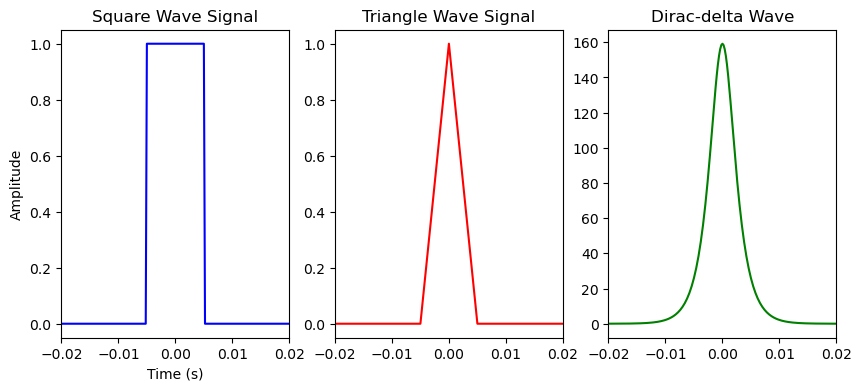

In [2]:
#creating time axis + parameters
dt = 0.0002
N = 50000
t = (np.arange(N) - N // 2) * dt 
width = 0.01 #delta epsilon in seconds
time_delay = 0.0 #time delay/shift
skew = 0.5 # for triangle signal: 0.5 = symmetric, 1 = right ramp

#creating signal waves
square = np.where(np.abs(t-time_delay) <= width / 2.0,1.0,0.0)

#triangle wave param
t_norm = ((t-time_delay)+ width/2.0)/width
p = np.clip(skew,0.01,0.99)
triangle = np.where(np.abs(t-time_delay) <= width/2.0, np.where(t_norm <p, t_norm / p, (1.0 - t_norm)/(1.0-p)),0.0)

#dirac delta
eps = 0.002
arg = np.clip((t - time_delay) / eps, -700, 700) #avoids overflow due to cosh
dirac = (1.0 / (np.pi * eps)) / np.cosh(arg)
dirac_norm = dirac / np.max(dirac)  #normalizing to scale with other waveforms in plot

fig, axs = plt.subplots(1,3,figsize = (10,4))
axs[0].plot(t, square, color = 'blue')
axs[0].set_title('Square Wave Signal')
axs[0].set_xlabel('Time (s)')
axs[0].set_ylabel('Amplitude')
axs[0].set_xlim(-0.02,0.02)

axs[1].plot(t, triangle, color = 'red')
axs[1].set_title('Triangle Wave Signal')
axs[1].set_xlim(-0.02,0.02)

axs[2].plot(t,dirac, color='green')
axs[2].set_title("Dirac-delta Wave")
axs[2].set_xlim(-0.02,0.02)
fig.show()

In [3]:
# Fourier transforms
freqs = np.fft.fftshift(np.fft.fftfreq(N, d=dt))
x_sq = np.fft.fftshift(np.fft.fft(square)) * dt
x_tr = np.fft.fftshift(np.fft.fft(triangle)) * dt
x_dr = np.fft.fftshift(np.fft.fft(dirac)) * dt

# Magnitudes
mag_sq = np.abs(x_sq)
mag_tr = np.abs(x_tr)
mag_dr = np.abs(x_dr)

mag_sq_norm = mag_sq / np.max(mag_sq)
mag_tr_norm = mag_tr / np.max(mag_tr)
mag_dr_norm = mag_dr / np.max(mag_dr)

# Masking / phase
def get_clean_phase(X, mag_norm, unwrap=True):
    phase = np.angle(X)
    phase[mag_norm < 1e-2] = np.nan
    if unwrap:
        valid = ~np.isnan(phase)
        phase[valid] = np.unwrap(phase[valid])
    return phase

phase_sq = get_clean_phase(x_sq, mag_sq_norm)
phase_tr = get_clean_phase(x_tr, mag_tr_norm)
phase_dr = get_clean_phase(x_dr, mag_dr_norm)


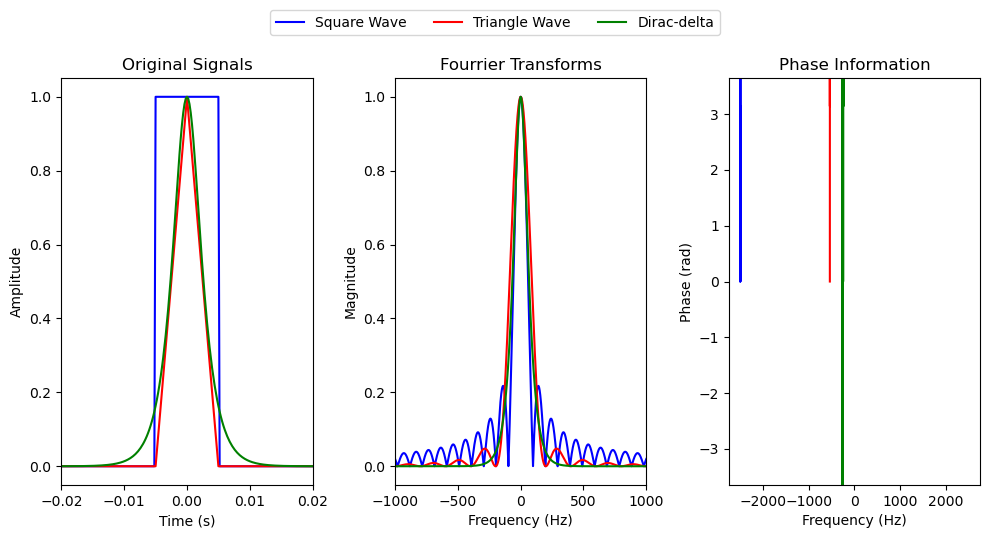

In [4]:
#plotting
fig, axs = plt.subplots(1, 3, figsize=(10, 5))
#Original Signal
axs[0].plot(t, square, color='blue', label ='Square Wave')
axs[0].plot(t, triangle, color ='red', label='Triangle Wave')
axs[0].plot(t, dirac_norm, color='green', label='Dirac-delta')
axs[0].set_title('Original Signals')
axs[0].set_xlabel('Time (s)')
axs[0].set_ylabel('Amplitude')
axs[0].set_xlim(-0.02,0.02)

#Fourier Transforms
axs[1].plot(freqs, mag_sq_norm, color='blue', label='Square Wave')
axs[1].plot(freqs, mag_tr_norm, color='red', label='Triangle Wave')
axs[1].plot(freqs, mag_dr_norm, color='green', label = 'Dirac-delta')
axs[1].set_title('Fourrier Transforms')
axs[1].set_xlabel('Frequency (Hz)')
axs[1].set_ylabel('Magnitude')
axs[1].set_xlim(-1000,1000)

#Phase Information
axs[2].plot(freqs, phase_sq, color='blue', label='Square Wave')
axs[2].plot(freqs, phase_tr, color='red', label='Triangle Wave')
axs[2].plot(freqs, phase_dr, color='green', label='Dirac-delta')
axs[2].set_title('Phase Information')
axs[2].set_xlabel('Frequency (Hz)')
axs[2].set_ylabel('Phase (rad)')
axs[2].set_xlim()
axs[2].set_ylim(-np.pi - 0.5, np.pi + 0.5)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(0.5, 1.08),ncol=3,frameon=True,)
plt.tight_layout()
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [5]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 8000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

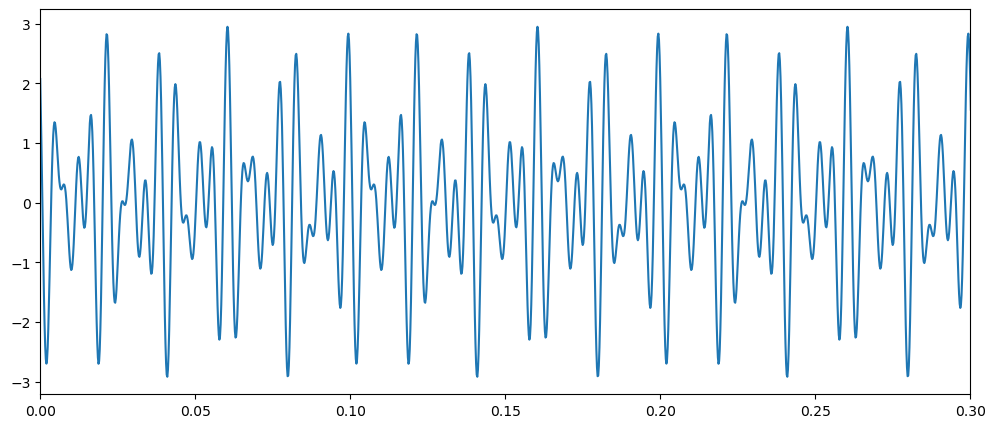

In [6]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

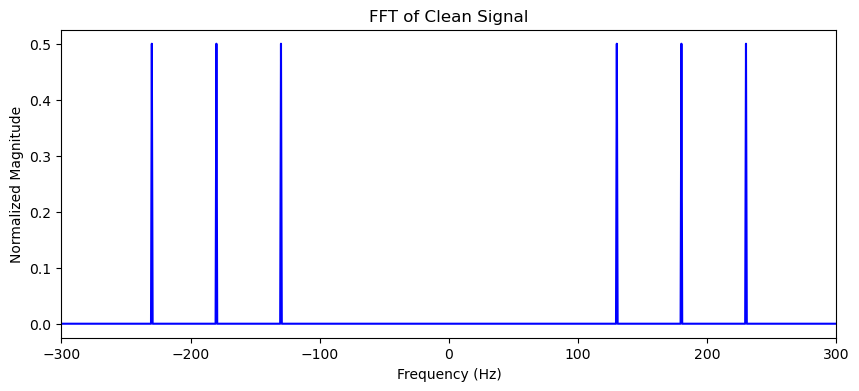

In [7]:
#Fast fourrier transform on clean/original data
fft = np.fft.fft(signal_original)
freq_axis = np.fft.fftfreq(N,dt)

#shifting zero frequency to center for plotting purposes
freq_shifted = np.fft.fftshift(freq_axis)
clean_shifted = np.fft.fftshift(np.abs(fft)) /N

#plotting fft of clean signal
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(freq_shifted, clean_shifted, color ='blue')
ax.set_title('FFT of Clean Signal')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Normalized Magnitude')
ax.set_xlim(-300,300)
fig.show()

In [8]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5


(0.0, 0.3)

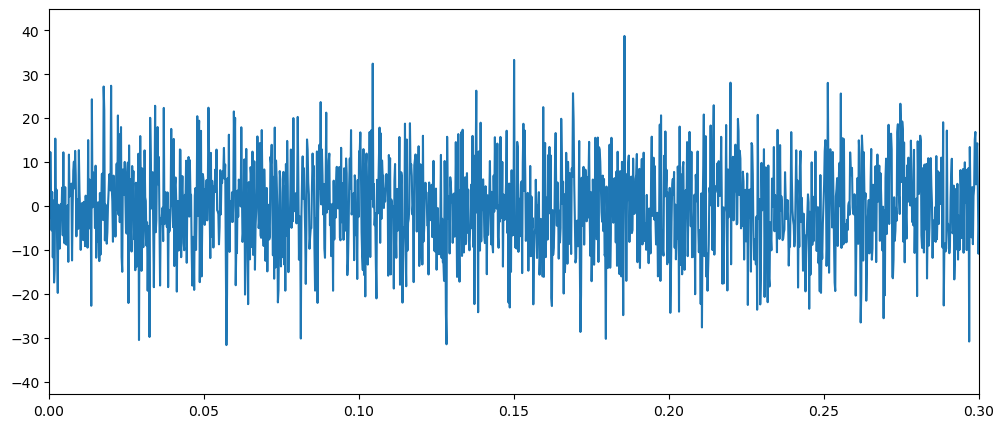

In [9]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

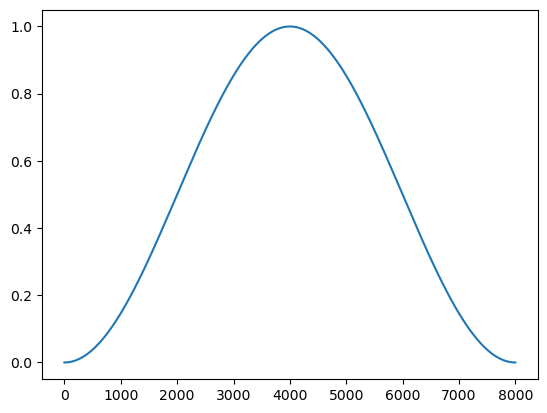

In [10]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [11]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


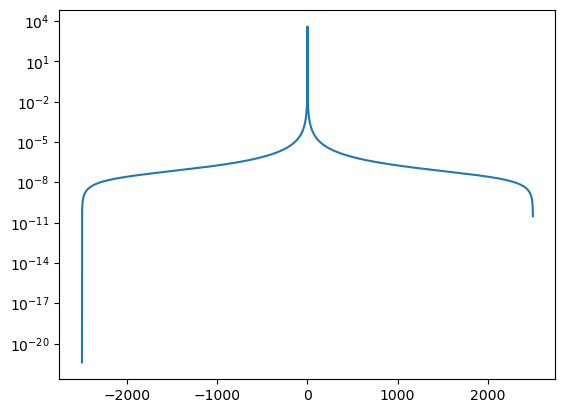

In [12]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

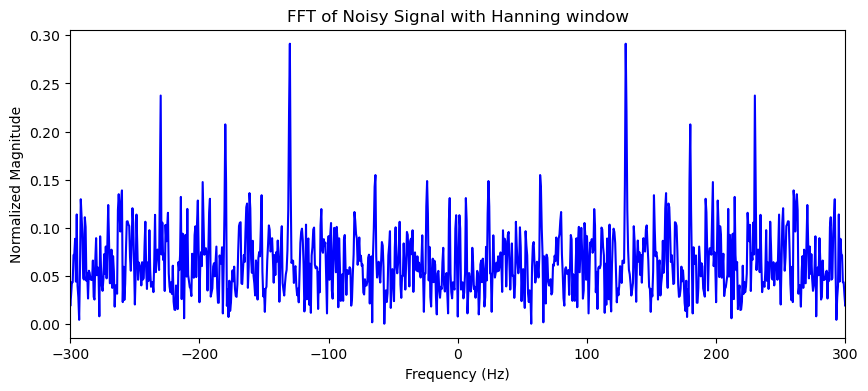

In [13]:
fft_noise = np.fft.fft(noisy_data*window)/N
noise_shifted = np.fft.fftshift(fft_noise)
noisySigPeaks = np.abs(noise_shifted)

#plotting fft of noisy signal signal
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(freq_shifted, noisySigPeaks, color ='blue')
ax.set_title('FFT of Noisy Signal with Hanning window')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Normalized Magnitude')
ax.set_xlim(-300,300)
fig.show()

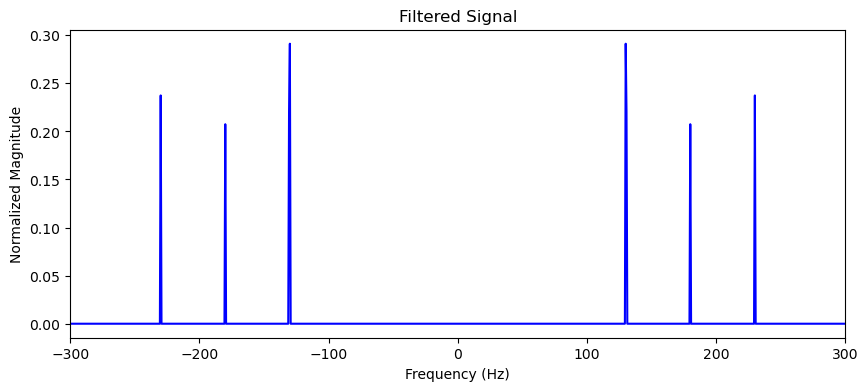

In [14]:
# From graph most of the noise are locateda at around 2000 - 3000
threshold = 0.2 #originally 3000 changed to 0.15 for normalized N to scale with differing N values
cleaned = fft_noise.copy()
cleaned[np.abs(fft_noise)<threshold] = 0 #sets components below threshold as 0
cleaned_shifted = np.fft.fftshift(cleaned)
cleanedSigPeaks = np.abs(cleaned_shifted)

#plotting fft of filtered signal
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(freq_shifted, cleanedSigPeaks, color ='blue')
ax.set_title('Filtered Signal')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Normalized Magnitude')
ax.set_xlim(-300,300)
fig.show()

In [15]:
#converting cleaned fft back to time domain
converted_windowed = np.fft.ifft(cleaned).real*N

#removing window
"""
converted = converted_windowed/window #causes divide by zero error
converted = converted_windowed/np.mean(window) #causes amplitude loss
converted = np.divide(converted_windowed,window,out=np.zeros_like(converted_windowed),where=(window > 1e-4),)
$blows up near zero
converted = 2*converted_windowed/np.mean(window) #added scaling factor to compensate magnitude loss but causes amplitude gain for N<25000
rewrite code to normalize N
"""
converted = converted_windowed/np.mean(window)

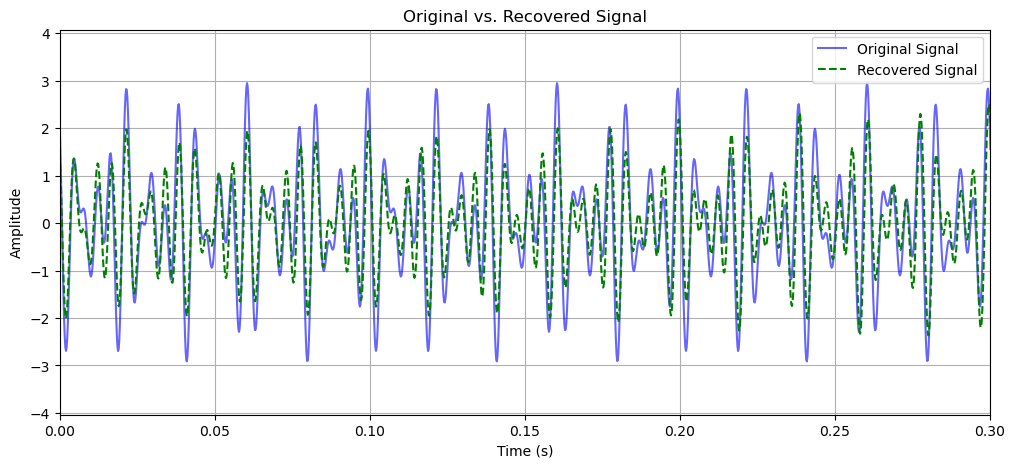

In [16]:
#plotting fft of noisy signal signal
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, signal_original, label="Original Signal", color="blue", alpha=0.6)
ax.plot(t_,converted,label="Recovered Signal",color="green",linestyle="--",)
ax.set_title("Original vs. Recovered Signal")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, 0.3)
ax.legend(loc="upper right")
ax.grid(True)
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

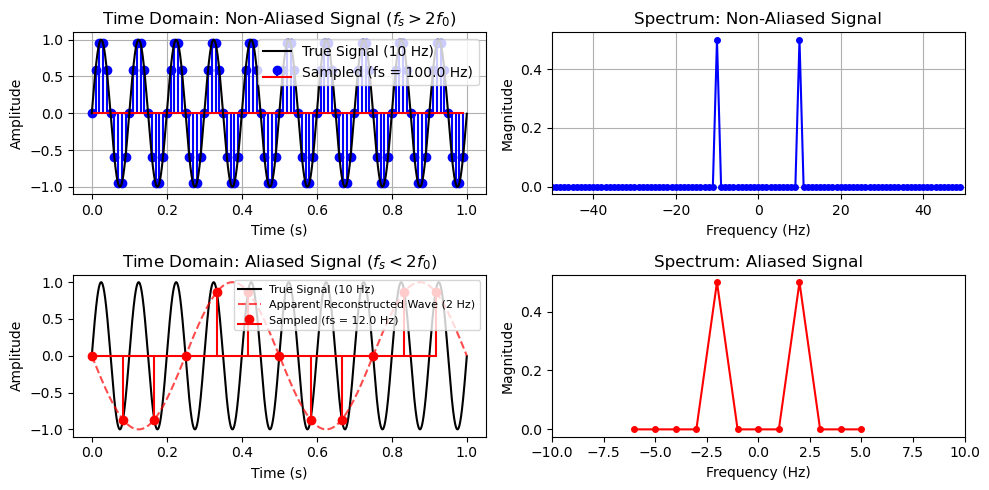

In [46]:
f_signal = 10.0      
t_duration = 1.0     

#nyquist Frequency is 2 * f_signal = 20 Hz
#sampling frequencies
fs_high = 100.0  #no aliasing
fs_low = 12.0    #w aliasing

#sinusoidal signal
dt_cont = 0.0001
t_cont = np.arange(0, t_duration, dt_cont)
signal_cont = np.sin(2 * np.pi * f_signal * t_cont)

#Uniform sampling
#aliasing
t_high = np.arange(0, t_duration, 1.0 / fs_high)
signal_high = np.sin(2 * np.pi * f_signal * t_high)

#no aliasing
t_low = np.arange(0, t_duration, 1.0 / fs_low)
signal_low = np.sin(2 * np.pi * f_signal * t_low)

#fft
#no aliasing
N_high = len(t_high)
freqs_high = np.fft.fftshift(np.fft.fftfreq(N_high, d=1.0 / fs_high))
X_high = np.fft.fftshift(np.fft.fft(signal_high)) / N_high

#w aliasing
N_low = len(t_low)
freqs_low = np.fft.fftshift(np.fft.fftfreq(N_low, d=1.0 / fs_low))
X_low = np.fft.fftshift(np.fft.fft(signal_low)) / N_low

# 4. PLOTTING
fig, axs = plt.subplots(2, 2, figsize=(10, 5))

axs[0, 0].plot(t_cont, signal_cont, 'k', label='True Signal (10 Hz)',zorder=5)
axs[0, 0].stem(t_high, signal_high, linefmt='b-', markerfmt='bo', basefmt='r-', label=f'Sampled (fs = {fs_high} Hz)')
axs[0, 0].set_title('Time Domain: Non-Aliased Signal ($f_s > 2 f_0$)')
axs[0, 0].set_xlabel('Time (s)')
axs[0, 0].set_ylabel('Amplitude')
axs[0, 0].grid(True)
axs[0, 0].legend(loc='upper right')

axs[0, 1].plot(freqs_high, np.abs(X_high), 'b-o', markersize=4)
axs[0, 1].set_title('Spectrum: Non-Aliased Signal')
axs[0, 1].set_xlabel('Frequency (Hz)')
axs[0, 1].set_ylabel('Magnitude')
axs[0, 1].set_xlim(-50, 50)
axs[0, 1].grid(True)

#perceived apparent freq =  |10 - 12| = 2 Hz
signal_apparent = np.sin(2 * np.pi * 2.0 * t_cont)
axs[1, 0].plot(t_cont, signal_cont, 'k', label='True Signal (10 Hz)')
axs[1, 0].plot(t_cont, -signal_apparent, 'r--', alpha=0.7, label='Apparent Reconstructed Wave (2 Hz)')
axs[1, 0].stem(t_low, signal_low, linefmt='r-', markerfmt='ro', basefmt='r-', label=f'Sampled (fs = {fs_low} Hz)')
axs[1, 0].set_title('Time Domain: Aliased Signal ($f_s < 2 f_0$)')
axs[1, 0].set_xlabel('Time (s)')
axs[1, 0].set_ylabel('Amplitude')
axs[1, 0].legend(loc='upper right', fontsize=8)


axs[1, 1].plot(freqs_low, np.abs(X_low), 'r-o', markersize=4)
axs[1, 1].set_title('Spectrum: Aliased Signal')
axs[1, 1].set_xlabel('Frequency (Hz)')
axs[1, 1].set_ylabel('Magnitude')
axs[1, 1].set_xlim(-10, 10)

plt.tight_layout()
plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [18]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

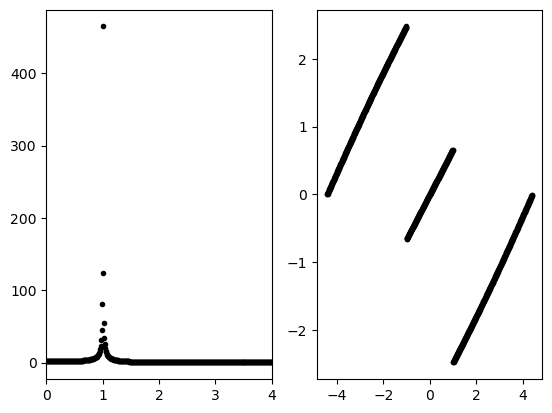

In [19]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [20]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

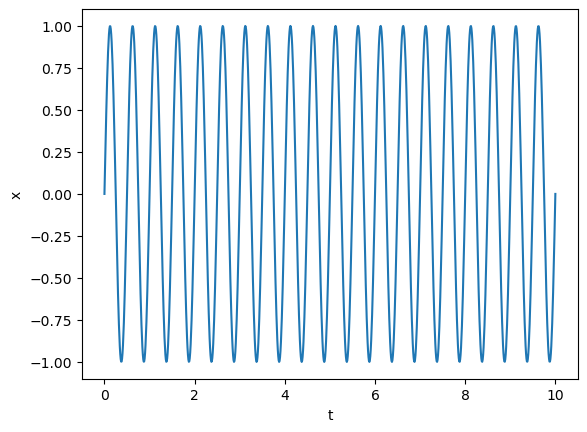

In [21]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [22]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

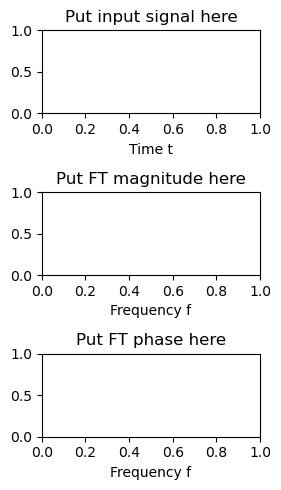

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

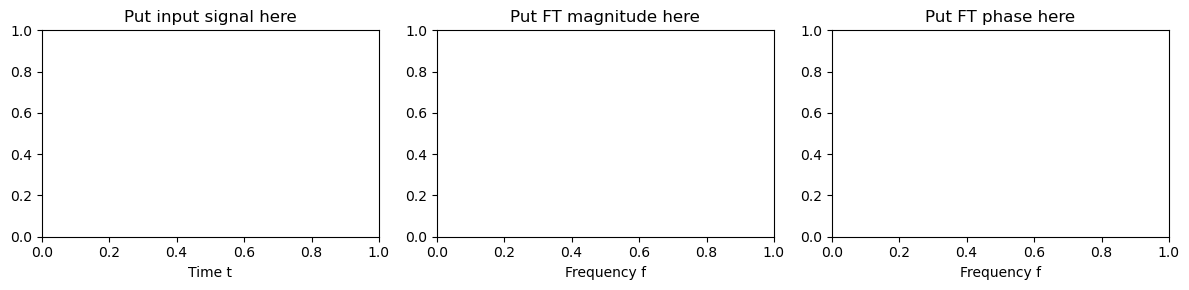

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

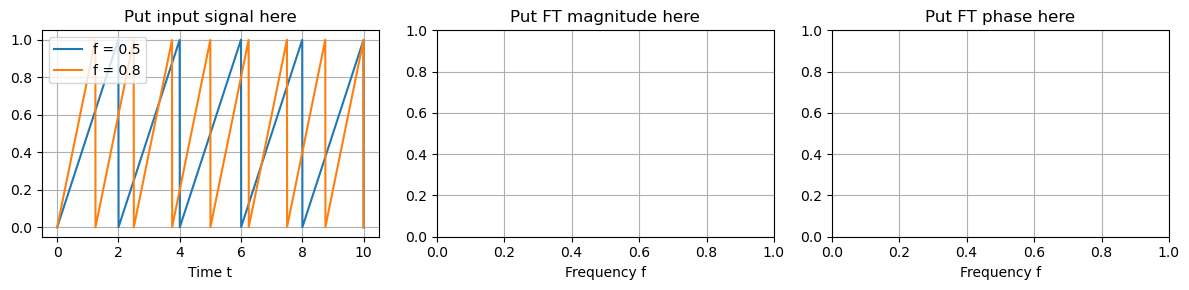

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [26]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



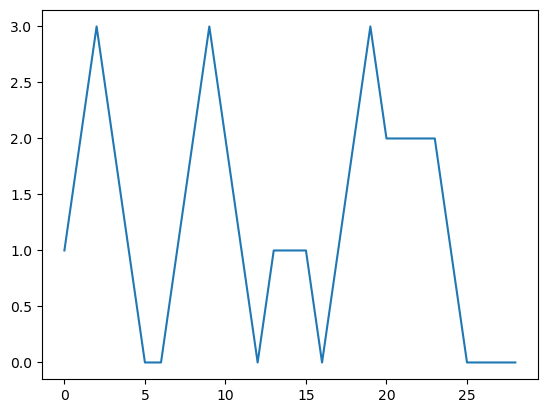

In [27]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [28]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [29]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

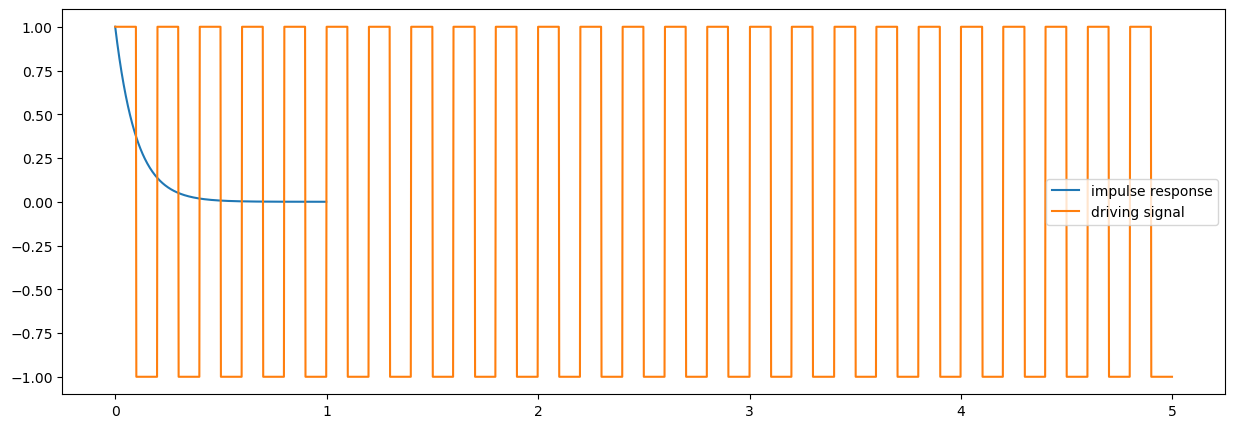

In [30]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [31]:
response = np.convolve(input_signal, h_t, mode = "same")

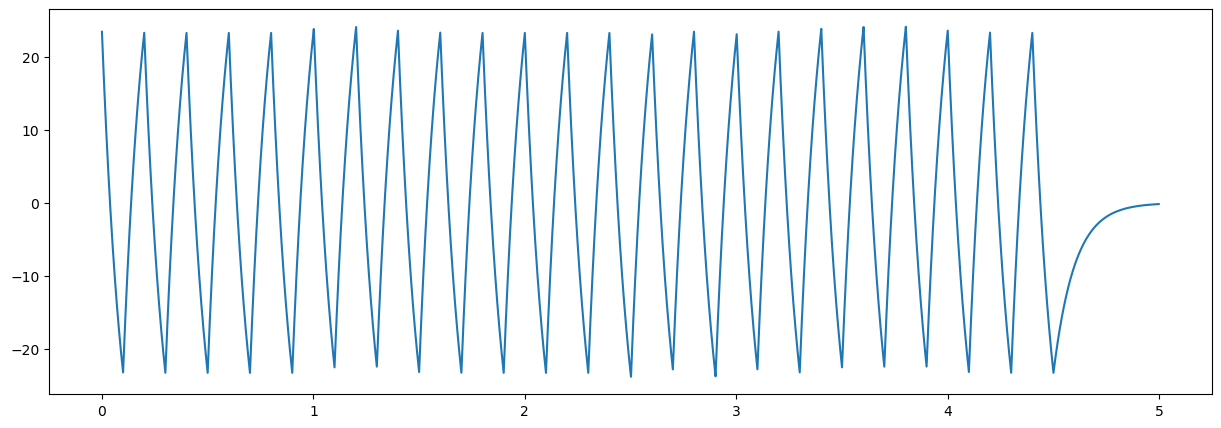

In [32]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [33]:
fourier_length = len(h_t) + len(input_signal) - 1

In [34]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [35]:
fourier_response = fourier_h*fourier_input 

In [36]:
response = np.real(np.fft.ifft(fourier_response))

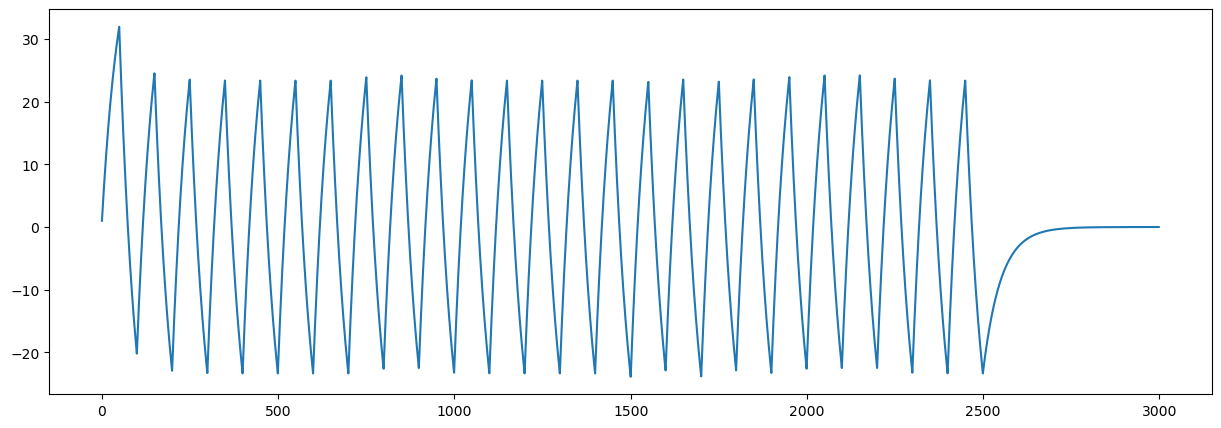

In [37]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)